# Mie scattering tutorial

This tutorial shows how to use `mie_perso` to compute the scattering matrix of
homogeneous spheres with Mie theory ([PyMieScatt](https://pymiescatt.readthedocs.io)),
spread over all the CPUs of your machine, and how to integrate it over a particle
size distribution to produce the single-scattering input of a radiative transfer
code such as OSOAA.

You will:

1. compute the scattering matrix of a single sphere;
2. see how it changes with the size parameter and the wavelength;
3. build a look-up table over size parameters and integrate it over a log-normal
   size distribution of particles in water;
4. derive the mean cross sections and write an OSOAA scattering-matrix file.

## Conventions

- **Size parameter**: $x = 2\pi r / \lambda = \pi d / \lambda$, with $r$ (resp. $d$)
  the particle radius (resp. diameter) and $\lambda$ the wavelength **in the medium**
  surrounding the particle.
- **Refractive index**: $m = n + ik$ is the complex refractive index of the particle
  **relative to the medium**. Absorption corresponds to $k > 0$ (PyMieScatt convention);
  a negative $k$ gives a negative absorption efficiency.
- **Scattering matrix**: for spheres, only four elements are independent,
  $F_{11} = F_{22}$, $F_{12} = F_{21}$, $F_{33} = F_{44}$ and $F_{34} = -F_{43}$,
  all other elements being zero. They are returned as `S11`, `S12`, `S33`, `S34`.
- **Normalization**: the phase function $F_{11}$ is normalized such that
  $\frac{1}{2}\int_0^\pi F_{11}(\theta)\sin\theta\, d\theta = 1$; the other elements
  are shown relative to $F_{11}$ (degree of linear polarization $-F_{12}/F_{11}$, etc.).
- **Angles**: scattering angles $\theta$ are in radians.

In [1]:
import os

import numpy as np
import xarray as xr
from scipy.integrate import trapezoid
import matplotlib as mpl
import matplotlib.pyplot as plt

from mie_perso import PSD, Processor, SizeParam

plt.rcParams.update({'font.family': 'serif', 'mathtext.fontset': 'stix',
                     'font.size': 14, 'axes.labelsize': 16})

# directory where the (costly) look-up tables and the outputs are saved
odir = os.path.join('..', 'data')
os.makedirs(odir, exist_ok=True)

## Load the multi-processor Mie object

`Processor` distributes the computations over `processes` workers (all CPUs by default).

In [2]:
pmie = Processor()
print('number of workers:', pmie.processes)

number of workers: 40


Helper functions used throughout the notebook to plot the four independent terms
of the scattering matrix and to normalize the phase function.

In [3]:
def phase_function_norm(S11, theta):
    '''Normalization factor such that 1/2 * int F11 sin(theta) dtheta = 1'''
    return trapezoid(S11 * np.sin(theta), theta, axis=-1) / 2


def plot_mueller(mueller, dim, label, cmap=plt.cm.Spectral_r):
    '''Plot F11 (normalized) and F12/F11, F33/F11, F34/F11 for every value along `dim`.'''
    theta = mueller.theta.values
    ang = np.degrees(theta)
    values = np.atleast_1d(mueller[dim].values)
    norm = mpl.colors.Normalize(vmin=values.min(), vmax=values.max())

    fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), sharex=True)
    for value in values:
        mat = mueller.sel({dim: value}) if mueller[dim].ndim else mueller
        S11 = mat.S11.values
        color = cmap(norm(value)) if len(values) > 1 else 'k'
        axs[0, 0].plot(ang, S11 / phase_function_norm(S11, theta), color=color, lw=1)
        axs[0, 1].plot(ang, mat.S12 / S11, color=color, lw=1)
        axs[1, 0].plot(ang, mat.S33 / S11, color=color, lw=1)
        axs[1, 1].plot(ang, mat.S34 / S11, color=color, lw=1)

    axs[0, 0].semilogy()
    for ax, ylabel in zip(axs.ravel(), [r'$F_{11}$', r'$F_{12}/F_{11}$', r'$F_{33}/F_{11}$', r'$F_{34}/F_{11}$']):
        ax.set_ylabel(ylabel)
        ax.minorticks_on()
    for ax in axs.ravel()[1:]:
        ax.set_ylim([-1.05, 1.05])
    for ax in axs[-1]:
        ax.set_xlabel(r'Scattering angle (deg)')

    if len(values) > 1:
        sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
        cb = fig.colorbar(sm, ax=axs, shrink=0.6, aspect=30, pad=0.08, location='bottom')
        cb.set_label(label)
    return fig, axs

## Scattering matrix of a single sphere

Set the input parameters:

- the complex refractive index $m = n + ik$ relative to the medium;
- the size parameter(s) $x$, given as a list or an array;
- the scattering angles `theta` in radians.

`ScatMat_mp` returns an `xarray.Dataset` with the four non-null terms on the `(x, theta)` dimensions.

In [4]:
# refractive index relative to the medium (k > 0 for absorption)
m = 1.17 + 0.001j

# size parameter
x = [50]

# scattering angles in radians
theta = np.linspace(0, np.pi, 3600)

scat_mat = pmie.ScatMat_mp(m, x, theta)
scat_mat

<xarray.Dataset> Size: 144kB
Dimensions:  (x: 1, theta: 3600)
Coordinates:
  * x        (x) int64 8B 50
  * theta    (theta) float64 29kB 0.0 0.0008729 0.001746 ... 3.14 3.141 3.142
    nr       float64 8B 1.17
    ni       float64 8B 0.001
Data variables:
    S11      (x, theta) float64 29kB 2.288e+06 2.287e+06 ... 2.781e+03 2.784e+03
    S12      (x, theta) float64 29kB 0.0 0.1622 0.6457 ... 1.356 0.3395 0.0
    S33      (x, theta) float64 29kB 2.288e+06 2.287e+06 ... -2.784e+03
    S34      (x, theta) float64 29kB 0.0 36.08 144.1 323.7 ... 6.942 1.739 0.0
Attributes:
    description:  non-null scattering matrix terms from Mie computations usin...

### Visualization of the full scattering matrix

The 16 elements of the matrix, with the zero elements shown as horizontal lines.

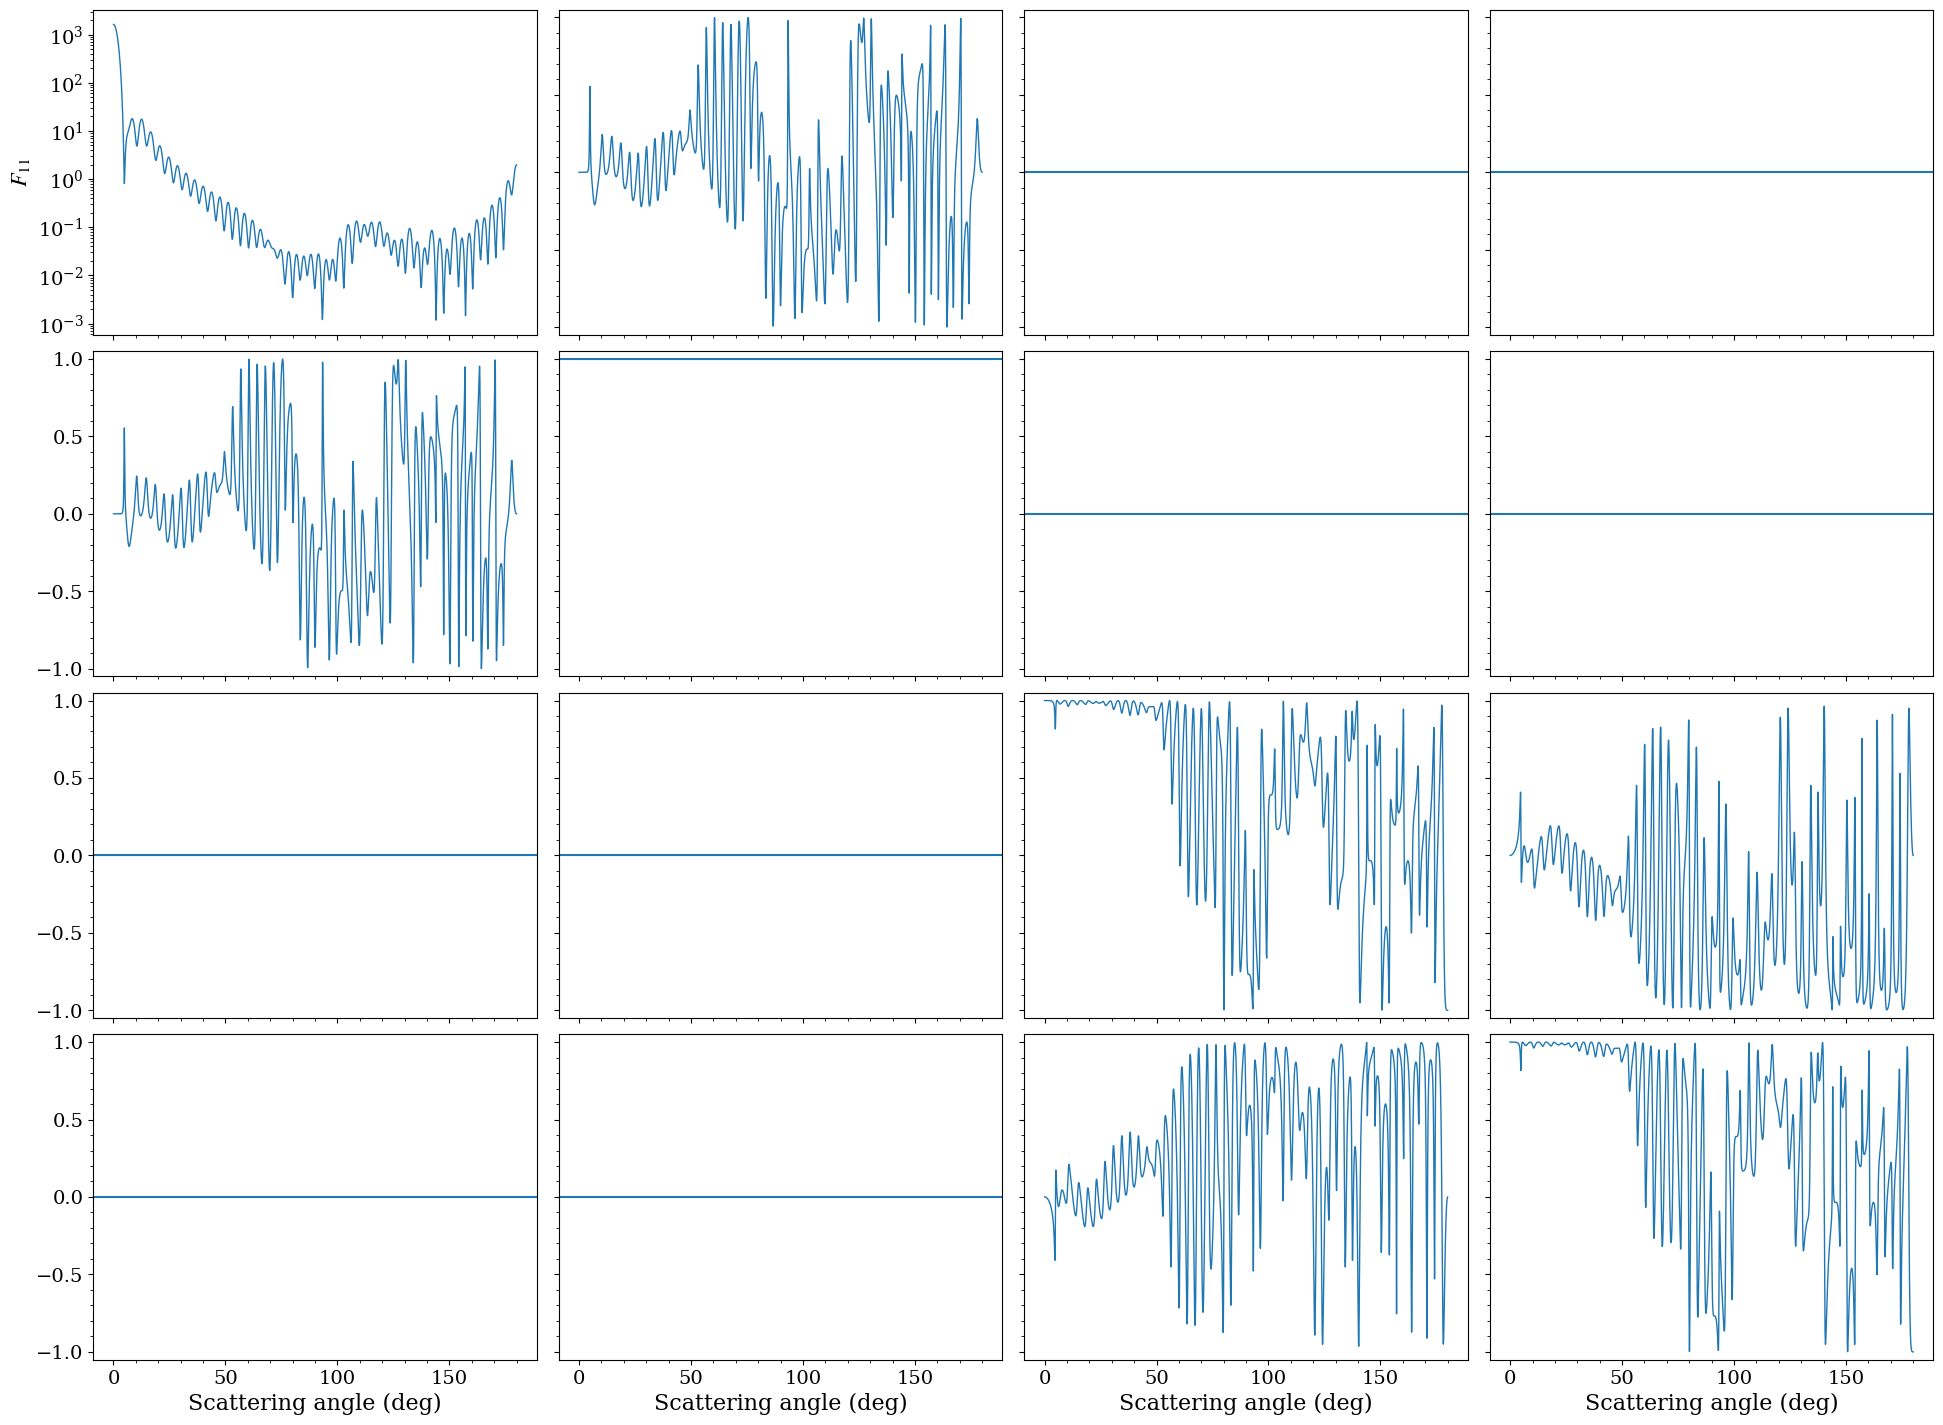

In [5]:
ang = np.degrees(theta)
S11, S12, S33, S34 = [scat_mat[v].squeeze().values for v in ['S11', 'S12', 'S33', 'S34']]

fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(20, 15), sharex=True)
fig.subplots_adjust(bottom=0.08, top=0.98, left=0.06, right=0.98, hspace=0.05, wspace=0.05)

axs[0, 0].plot(ang, S11 / phase_function_norm(S11, theta), lw=1)
axs[0, 0].semilogy()
axs[0, 0].set_ylabel(r'$F_{11}$')
# F12 = F21, F22 = F11, F33 = F44, F34 = -F43
for (i, j), y in {(0, 1): S12 / S11, (1, 0): S12 / S11, (2, 2): S33 / S11, (3, 3): S33 / S11,
                  (2, 3): S34 / S11, (3, 2): -S34 / S11}.items():
    axs[i, j].plot(ang, y, lw=1)
axs[1, 1].axhline(1)
for i, j in [(0, 2), (0, 3), (1, 2), (1, 3), (2, 0), (3, 0), (2, 1), (3, 1)]:
    axs[i, j].axhline(0)

for i in range(4):
    for j in range(1, 4):
        axs[i, j].set_yticklabels([])
    axs[-1, i].set_xlabel('Scattering angle (deg)')
for ax in axs.ravel()[1:]:
    ax.set_ylim([-1.05, 1.05])
for ax in axs.ravel():
    ax.minorticks_on()

Only four terms are independent: plot them with the helper function.

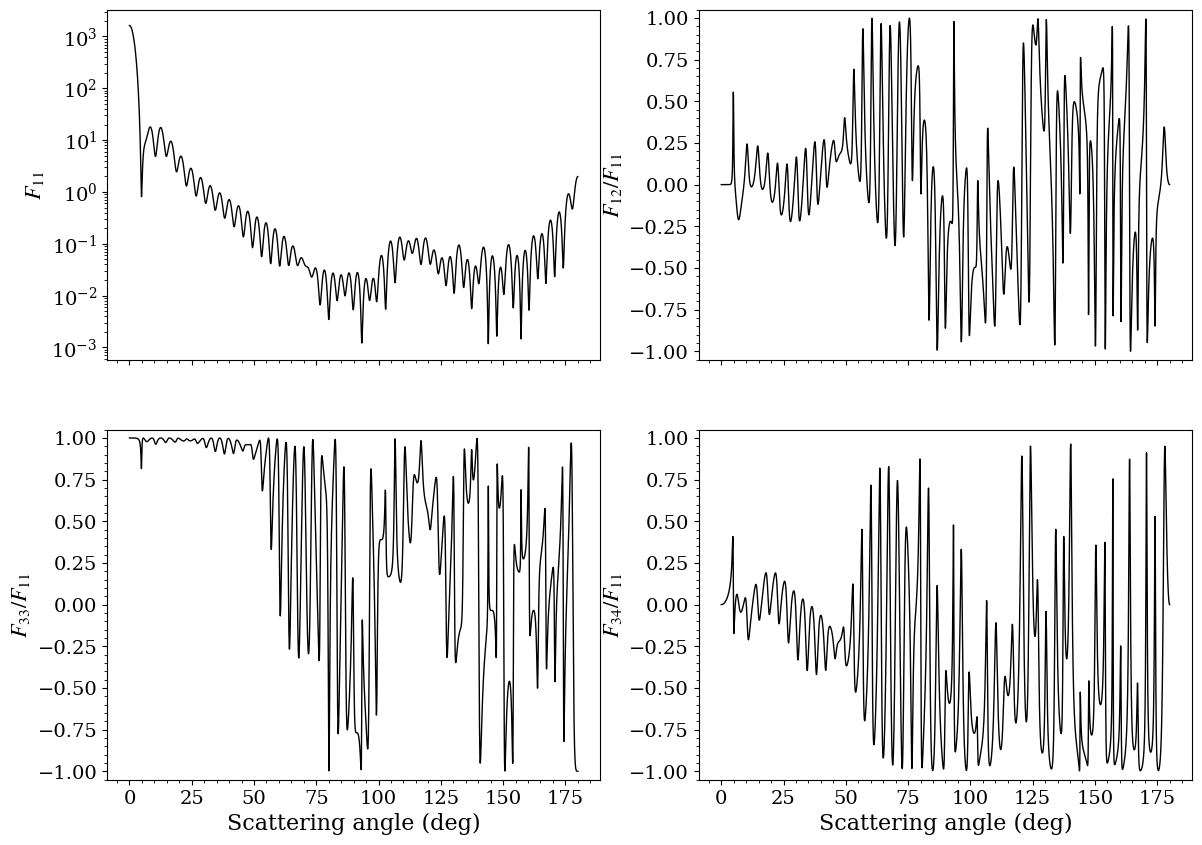

In [6]:
plot_mueller(scat_mat, 'x', 'Size parameter $x$ (-)');

## Series of size parameters

The computation of each size parameter is sent to a different worker.

In [7]:
m = 1.17 + 0.001j
x = np.linspace(1, 50, 10)
theta = np.linspace(0, np.pi, 3600)

scat_mat = pmie.ScatMat_mp(m, x, theta)
scat_mat

<xarray.Dataset> Size: 1MB
Dimensions:  (x: 10, theta: 3600)
Coordinates:
  * x        (x) float64 80B 1.0 6.444 11.89 17.33 ... 33.67 39.11 44.56 50.0
  * theta    (theta) float64 29kB 0.0 0.0008729 0.001746 ... 3.14 3.141 3.142
    nr       float64 8B 1.17
    ni       float64 8B 0.001
Data variables:
    S11      (x, theta) float64 288kB 0.01354 0.01354 ... 2.781e+03 2.784e+03
    S12      (x, theta) float64 288kB 0.0 -5.001e-09 -2e-08 ... 1.356 0.3395 0.0
    S33      (x, theta) float64 288kB 0.01354 0.01354 ... -2.781e+03 -2.784e+03
    S34      (x, theta) float64 288kB 0.0 -3.246e-12 -1.298e-11 ... 1.739 0.0
Attributes:
    description:  non-null scattering matrix terms from Mie computations usin...

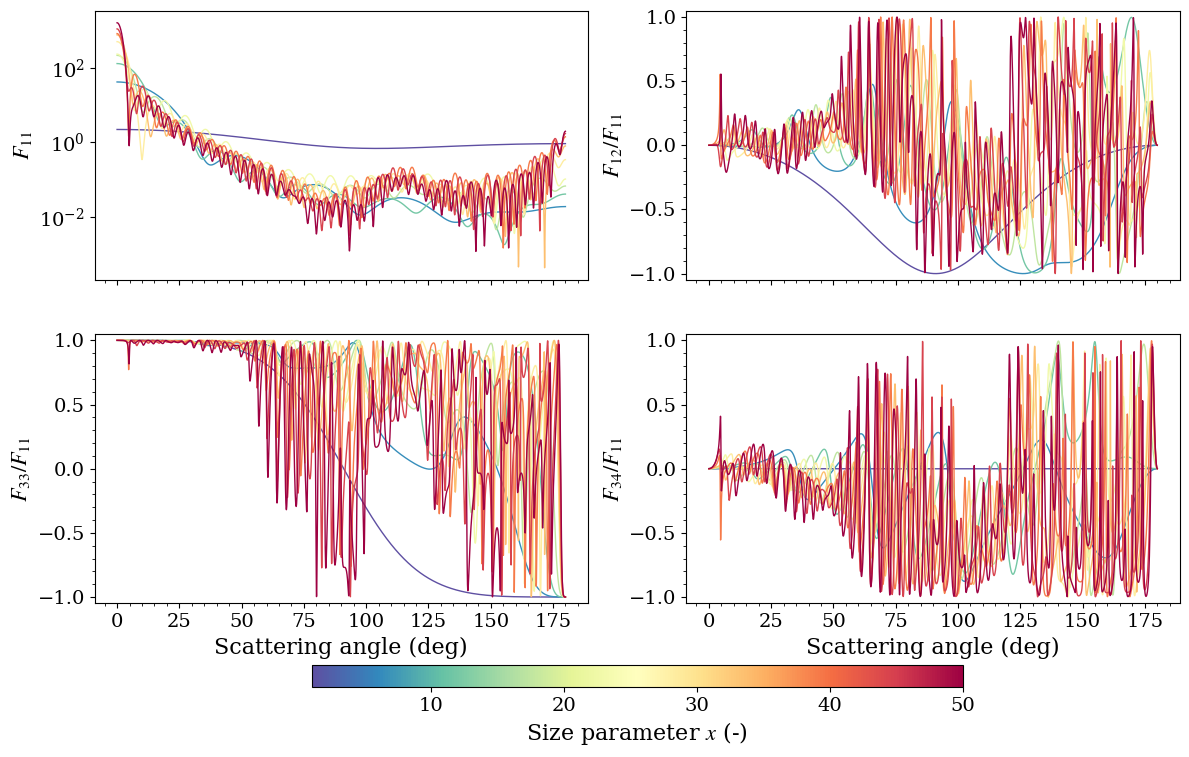

In [8]:
plot_mueller(scat_mat, 'x', 'Size parameter $x$ (-)');

### Spectral variation for a given particle

For a particle of given radius $r$, the size parameter varies with the wavelength as
$x = 2\pi r / \lambda$. Compute the scattering matrix for a set of wavelengths
(in the medium) and index it by wavelength.

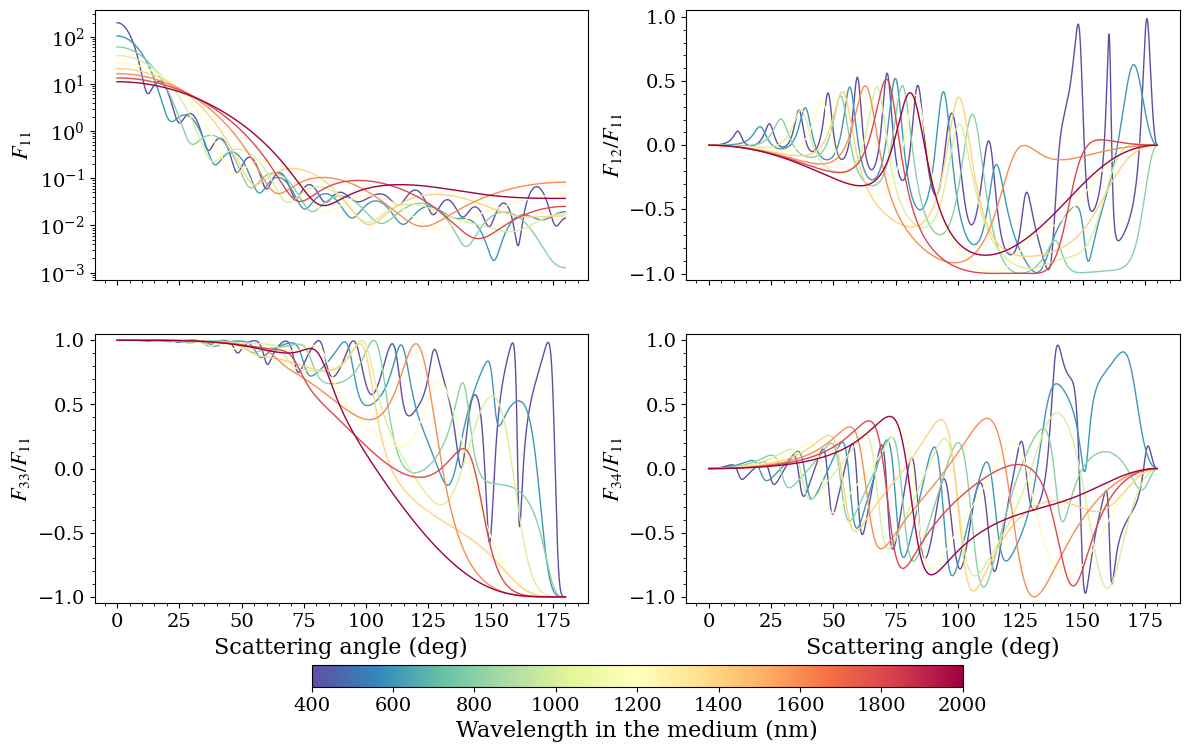

In [9]:
# particle radius in nm
radius = 1e3
# wavelengths in the medium in nm
wavelengths = np.linspace(400, 2000, 9)

x = 2 * np.pi * radius / wavelengths
scat_mat = pmie.ScatMat_mp(m, x, theta)
# index by wavelength instead of size parameter
scat_mat = scat_mat.assign_coords(wavelength=('x', wavelengths)).swap_dims(x='wavelength')

plot_mueller(scat_mat, 'wavelength', 'Wavelength in the medium (nm)');

Same particle with a lower and more absorbing refractive index: the absorption damps
the oscillations of the phase function and of the polarization terms.

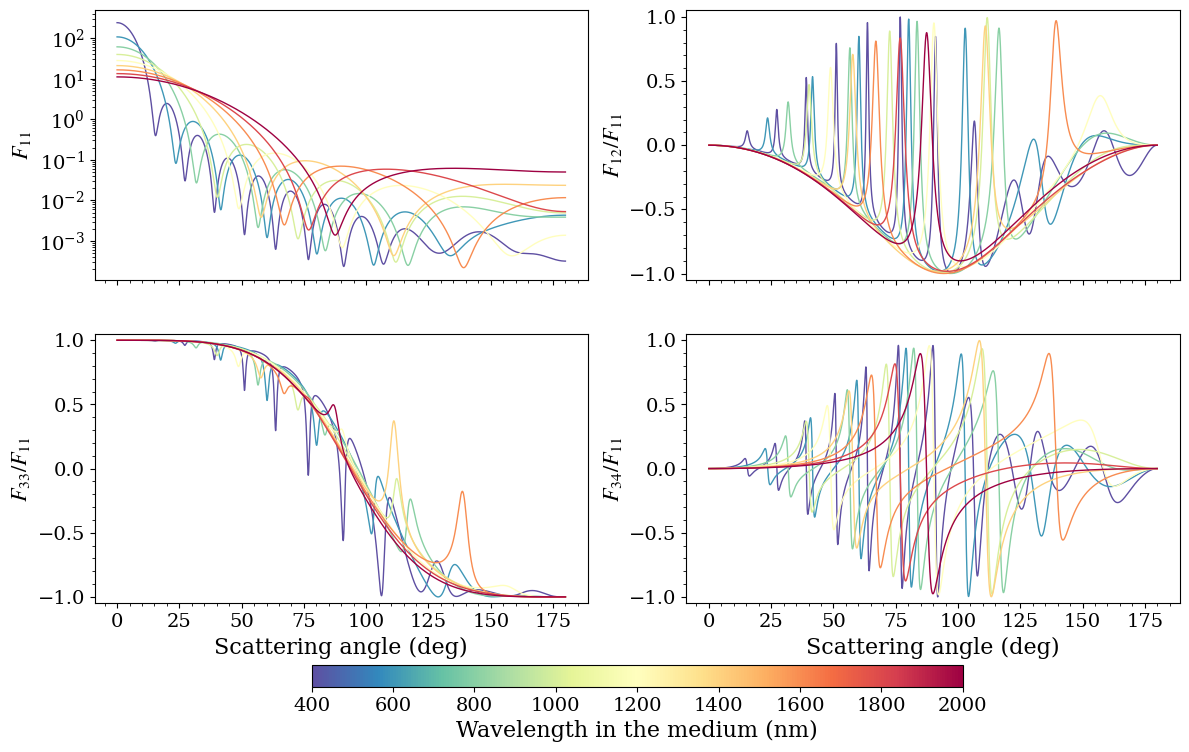

In [10]:
m = 1.05 + 0.02j

scat_mat = pmie.ScatMat_mp(m, x, theta)
scat_mat = scat_mat.assign_coords(wavelength=('x', wavelengths)).swap_dims(x='wavelength')

plot_mueller(scat_mat, 'wavelength', 'Wavelength in the medium (nm)');

## Particles in water: integration over a size distribution

For natural waters, the particles are polydisperse: the scattering properties of the
population are obtained by integrating the single-particle properties over the
particle size distribution (PSD) $n(r)$:

$$F_{ij}(\theta) = \frac{\lambda^2}{\pi} \frac{\int S_{ij}(x(r), \theta)\, n(r)\, dr}{\int n(r)\, dr},
\qquad
C_{sca} = \frac{\int Q_{sca}(x(r))\, \pi r^2\, n(r)\, dr}{\int n(r)\, dr}$$

with $\lambda$ the wavelength in water. With this definition,
$\frac{1}{2}\int_0^\pi F_{11}\sin\theta\, d\theta = C_{sca}$, the mean scattering cross
section of the particles.

```{warning}
The size parameter must be computed with the wavelength **in water**,
$\lambda_{medium} = \lambda_{vacuum} / n_{w}(\lambda_{vacuum})$, and the refractive
index of the particles must be **relative to water**.
```

### Look-up table over size parameters

Because $x$ only depends on $r/\lambda$, a single look-up table over $x$ covers all
the radii and wavelengths. It is saved into a netCDF file to be reused.

```{note}
With 501 size parameters up to $x = 4000$ and 3600 angles, the computation takes
about one minute on 40 CPUs (the cost increases with $x$).
```

In [11]:
def water_refractive_index(wl):
    '''Real refractive index of water, wl: wavelength in vacuum in nm'''
    return 1.3199 + 6878 / wl ** 2 - 1.132e9 / wl ** 4 + 1.11e14 / wl ** 6


# refractive index of the particles relative to water
m = 1.05 + 0.002j

theta = np.linspace(0, np.pi, 3600)
x = np.logspace(-1, np.log10(4000), 501)

ofile = os.path.join(odir, 'mueller_mie_' + format(m, '1.3f') + '_t3600_x501.nc')

if os.path.exists(ofile):
    mueller = xr.open_dataset(ofile)
else:
    mueller = pmie.ScatMat_mp(m, x, theta)
    mueller.to_netcdf(ofile)
mueller

<xarray.Dataset> Size: 58MB
Dimensions:  (x: 501, theta: 3600)
Coordinates:
  * x        (x) float64 4kB 0.1 0.1021 0.1043 ... 3.834e+03 3.916e+03 4e+03
  * theta    (theta) float64 29kB 0.0 0.0008729 0.001746 ... 3.14 3.141 3.142
    nr       float64 8B 1.05
    ni       float64 8B 0.002
Data variables:
    S11      (x, theta) float64 14MB 1.094e-09 1.094e-09 ... 2.383e+03 2.383e+03
    S12      (x, theta) float64 14MB 0.0 -4.167e-16 -1.667e-15 ... -0.01056 0.0
    S33      (x, theta) float64 14MB 1.094e-09 1.094e-09 ... -2.383e+03
    S34      (x, theta) float64 14MB 0.0 1.381e-21 5.523e-21 ... 0.00178 0.0
Attributes:
    description:  non-null scattering matrix terms from Mie computations usin...

The efficiency factors (extinction, scattering, absorption, asymmetry parameter...)
are computed on the same size parameters.

In [12]:
Qeff = pmie.Qeff_mp(m, mueller.x.values)
Qeff

<xarray.Dataset> Size: 32kB
Dimensions:  (x: 501)
Coordinates:
  * x        (x) float64 4kB 0.1 0.1021 0.1043 ... 3.834e+03 3.916e+03 4e+03
    nr       float64 8B 1.05
    ni       float64 8B 0.002
Data variables:
    Qext     (x) float64 4kB 0.0005242 0.0005355 0.000547 ... 2.008 2.008 2.008
    Qsca     (x) float64 4kB 2.905e-07 3.162e-07 3.441e-07 ... 1.018 1.018 1.018
    Qabs     (x) float64 4kB 0.0005239 0.0005351 0.0005466 ... 0.9897 0.9897
    g        (x) float64 4kB 0.001631 0.001702 0.001775 ... 0.9981 0.9981 0.9981
    Qpr      (x) float64 4kB 0.0005242 0.0005355 0.000547 ... 0.9917 0.9916
    Qback    (x) float64 4kB 4.34e-07 4.723e-07 ... 0.0005958 0.0005958
    Qratio   (x) float64 4kB 1.494 1.494 1.493 ... 0.0005851 0.0005852 0.0005852

### Size distribution

Log-normal number distribution of median radius `rn_med` (µm) and geometric
standard deviation `sigma`, with its mean, effective radius and effective variance.

mean particle volume: 1.613e+03 µm^3


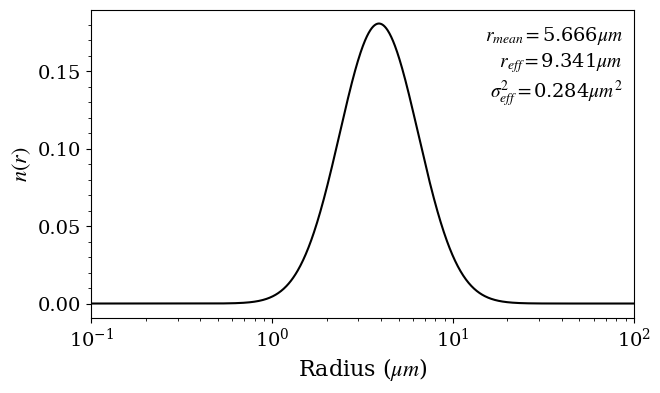

In [13]:
rn_med = 5.
sigma = 0.5

r = np.logspace(-2, 3, 2000)
ndp = PSD().lognorm(r, rn_med=rn_med, sigma=sigma)

# mean volume of the particles in µm^3
vol_mean = trapezoid(ndp * 4 / 3 * np.pi * r ** 3, r) / trapezoid(ndp, r)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(r, ndp, 'k')
ax.semilogx()
ax.set_xlim(0.1, 100)
ax.set_xlabel(r'Radius ($\mu m$)')
ax.set_ylabel(r'$n(r)$')
ax.minorticks_on()
ax.text(0.98, 0.95, SizeParam(r, ndp.copy()).to_annotation(), transform=ax.transAxes, ha='right', va='top')
print('mean particle volume: {:.3e} µm^3'.format(vol_mean))

### Integration over the size distribution

For each wavelength in vacuum, convert the size parameters of the look-up table into
radii and integrate the scattering matrix and the cross sections over the PSD.

In [14]:
def integrate_psd(mueller, Qeff, wavelength, psd):
    '''Scattering matrix and mean cross sections (µm^2) of a particle population.

    wavelength: wavelength in vacuum in nm
    psd: function returning the number size distribution n(r) for radii r in µm
    '''
    wl_medium = wavelength / water_refractive_index(wavelength) * 1e-3  # µm
    radius = mueller.x.values * wl_medium / (2 * np.pi)
    ndp = psd(radius)
    ndp_norm = trapezoid(ndp, radius)

    mueller_ = mueller.assign_coords(radius=('x', radius)).swap_dims(x='radius')
    scat_mat = (wl_medium ** 2 / np.pi * mueller_ * xr.DataArray(ndp, dims='radius')
                ).integrate('radius') / ndp_norm

    Qeff_ = Qeff.assign_coords(radius=('x', radius)).swap_dims(x='radius')
    geom = xr.DataArray(np.pi * radius ** 2 * ndp, dims='radius')
    cross_section = xr.Dataset({'Csca': (Qeff_.Qsca * geom).integrate('radius') / ndp_norm,
                                'Cext': (Qeff_.Qext * geom).integrate('radius') / ndp_norm})
    return (scat_mat.assign_coords(wavelength=wavelength),
            cross_section.assign_coords(wavelength=wavelength))


psd = lambda radius: PSD().lognorm(radius, rn_med=rn_med, sigma=sigma)

wavelengths = np.linspace(350, 1000, 27)
res = [integrate_psd(mueller, Qeff, wl, psd) for wl in wavelengths]
xscat_mat = xr.concat([r_[0] for r_ in res], dim='wavelength')
xCrossSection = xr.concat([r_[1] for r_ in res], dim='wavelength')
xscat_mat

<xarray.Dataset> Size: 3MB
Dimensions:     (wavelength: 27, theta: 3600)
Coordinates:
  * theta       (theta) float64 29kB 0.0 0.0008729 0.001746 ... 3.14 3.141 3.142
    nr          float64 8B 1.05
    ni          float64 8B 0.002
  * wavelength  (wavelength) float64 216B 350.0 375.0 400.0 ... 975.0 1e+03
Data variables:
    S11         (wavelength, theta) float64 778kB 9.088e+06 8.785e+06 ... 0.3109
    S12         (wavelength, theta) float64 778kB 0.0 20.09 ... 0.001424 0.0
    S33         (wavelength, theta) float64 778kB 9.088e+06 ... -0.3109
    S34         (wavelength, theta) float64 778kB 0.0 178.4 ... 0.004432 0.0

Check the results: the mean cross sections and the consistency of the normalization,
$\frac{1}{2}\int F_{11}\sin\theta\, d\theta = C_{sca}$.

In [15]:
xCrossSection['Csca_from_F11'] = (('wavelength',), phase_function_norm(xscat_mat.S11.values, theta))
xCrossSection.to_dataframe()[['Cext', 'Csca', 'Csca_from_F11']].head(10)

,Cext,Csca,Csca_from_F11
wavelength,,,
350.0,267.938758,180.310467,180.020903
375.0,268.526452,183.988942,183.739564
400.0,269.126268,187.421522,187.203613
425.0,269.756358,190.681047,190.488545
450.0,270.431821,193.816408,193.644863
475.0,271.165361,196.862693,196.708711
500.0,271.967448,199.846349,199.707269
525.0,272.846278,202.787808,202.661499
550.0,273.807727,205.702870,205.587596


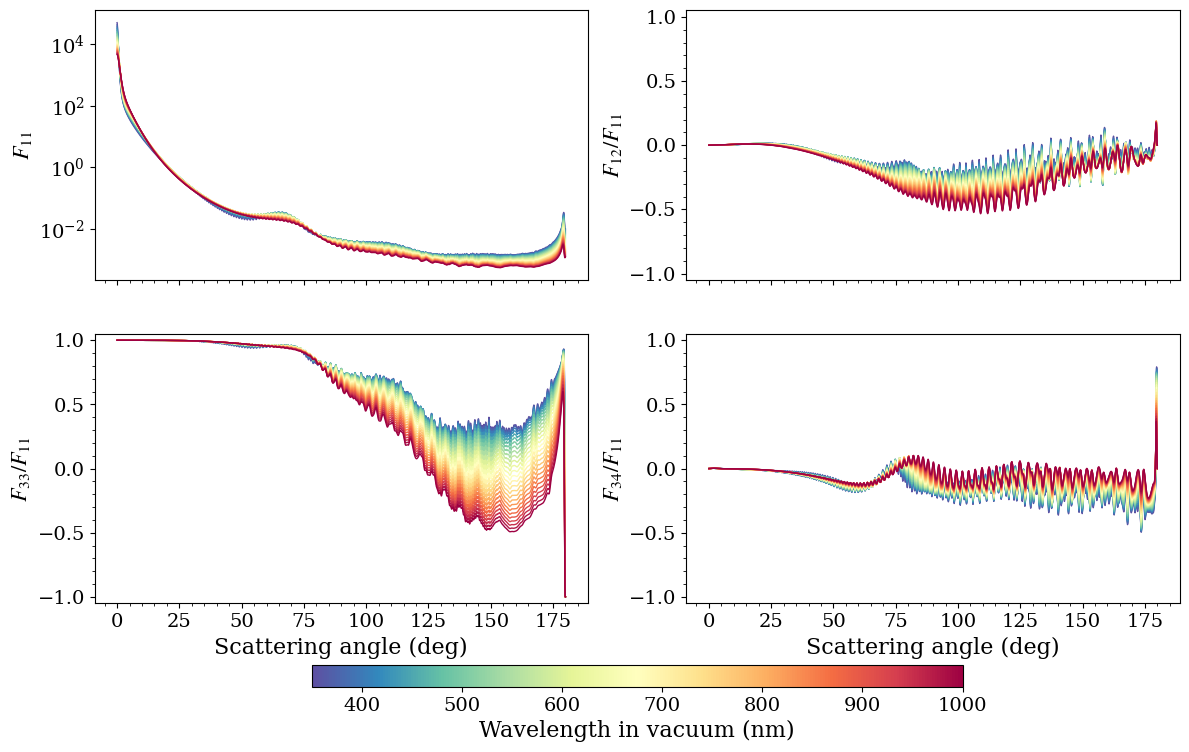

In [16]:
plot_mueller(xscat_mat, 'wavelength', 'Wavelength in vacuum (nm)');

## Export for OSOAA

Write the normalized scattering matrix at a given wavelength in the format of the
OSOAA single-scattering input file: a header with the extinction and scattering cross
sections (µm²), the mean particle volume (µm³) and the number of angles, followed by
the matrix elements $F_{11}$ (normalized), $F_{12}/F_{11}$, $F_{22}/F_{11}$ and
$F_{33}/F_{11}$ versus the scattering angle in degrees.

In [17]:
wavelength = 450.
scat_mat_, cross_section_ = integrate_psd(mueller, Qeff, wavelength, psd)

S11 = scat_mat_.S11
mat = xr.Dataset({'s11': S11 / phase_function_norm(S11.values, theta),
                  's12': scat_mat_.S12 / S11,
                  's22': S11 * 0 + 1,  # F22 = F11 for spheres
                  's33': scat_mat_.S33 / S11})
df_mat = mat.assign_coords(theta=np.degrees(mat.theta)).reset_coords(drop=True).to_pandas()

header = ('Cext : {:12.6e}\nCsca : {:12.6e}\nvol_mean : {:12.6e}\nNb angles : {}\n'
          .format(float(cross_section_.Cext), float(cross_section_.Csca), vol_mean, len(df_mat)))

ofile_osoaa = os.path.join(odir, 'osoaa_scatmat_lognorm_rnmed{}_sig{}_m{}_wl{}.txt'.format(
    rn_med, sigma, format(m, '1.3f'), wavelength))
with open(ofile_osoaa, 'w') as fp:
    fp.write(header)
df_mat.to_csv(ofile_osoaa, sep=' ', header=True, mode='a')

print(header)
df_mat.head()

Cext : 2.704318e+02
Csca : 1.938164e+02
vol_mean : 1.612798e+03
Nb angles : 3600



,s11,s12,s22,s33
theta,,,,
0.000000,27845.620671,0.000000,1.0,1.0
0.050014,27293.504142,0.000002,1.0,1.0
0.100028,25770.314441,0.000008,1.0,1.0
0.150042,23584.780863,0.000019,1.0,1.0
0.200056,21066.787059,0.000033,1.0,1.0
